# Pay analysis

### Questions to ask:
- How much salary data does this dataset actually have, and who's disclosing it?
- Among postings that do disclose pay, how does it vary by role bucket, seniority,
  and skill?
- Upwork postings disclose salary far more often than real job postings do
  (48.2% vs. 11.9%), and the deep-dive in `02_market_landscape` already flagged that
  Upwork's salary fields look like a self-set freelance bid range rather than an
  employer-stated pay band. Blending the two together would skew every number in
  this notebook toward gig-rate noise, so this notebook treats them as two separate
  pay analyses: traditional job postings, and Upwork gig work as its own,
  structurally different path to earn in this field.


## Preparation
- Import necessary packages
- Load data
    - cleaning logic is managed by the Python script in a separate file.
    - Display first few records to check if it loaded
- Data collection window

In [1]:
# --- Imports ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 100)

In [2]:
# Call functions to run source file check and clean up, prepare the dataframe
import sys
sys.path.append("../src")
from data_prep import load_and_clean

df = load_and_clean("../raw/gsearch_jobs.csv")
df.head()

,title,company_name,location,via,description,extensions,job_id,thumbnail,posted_at,schedule_type,work_from_home,salary,search_term,date_time,search_location,commute_time,salary_pay,salary_rate,salary_avg,salary_min,salary_max,salary_hourly,salary_yearly,salary_standardized,description_tokens,skills_list,ext_time,ext_salary_text,ext_flags,flag_health_insurance,flag_no_degree_mentioned,via_clean,hours_since_posted,posted_date,state,location_type,title_role,title_seniority,title_level_numeral
0,Data Analyst,Meta,Anywhere,via LinkedIn,"In the intersection of compliance and analytics, we are seeking an analytical and data-savvy sel...","['15 hours ago', '101K–143K a year', 'Work from home', 'Full-time']",eyJqb2JfdGl0bGUiOiJEYXRhIEFuYWx5c3QiLCJodGlkb2NpZCI6IlhBR01sSV93cUdRQUFBQUFBQUFBQUE9PSIsInV1bGUi...,https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcSGWd4ZbDsuXA2YQ7fwMam4nW4cokBZJJYHlWXaRfs&s,15 hours ago,Full-time,True,101K–143K a year,data analyst,2023-08-04 03:00:13.797776,United States,NaN,101K–143K,a year,122000.0,101000.0,143000.0,NaN,122000.0,122000.0,"['tableau', 'r', 'python', 'sql']","[tableau, r, python, sql]",[15 hours ago],[101K–143K a year],"[Work from home, Full-time]",False,False,LinkedIn,15.0,2023-08-03 12:00:13.797776,NaN,Remote,Data Analyst,Not specified,NaN
1,Data Analyst,ATC,United States,via LinkedIn,Job Title: Entry Level Business Analyst / Product Owner U.S. Citizens and those authorized to wo...,"['12 hours ago', 'Full-time', 'Health insurance']",eyJqb2JfdGl0bGUiOiJEYXRhIEFuYWx5c3QiLCJodGlkb2NpZCI6InJ4WUhwWTd4aTNRQUFBQUFBQUFBQUE9PSIsInV1bGUi...,https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcS9pL2p8JqLIXvaGeM9_bc7EXVkXWuBzWI204SfKIU&s,12 hours ago,Full-time,NaN,NaN,data analyst,2023-08-04 03:00:13.797776,United States,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,[],[],[12 hours ago],[],"[Full-time, Health insurance]",True,False,LinkedIn,12.0,2023-08-03 15:00:13.797776,NaN,Nationwide/Unspecified,Data Analyst,Not specified,NaN
2,Aeronautical Data Analyst,"Garmin International, Inc.","Olathe, KS",via Indeed,"Overview:\n\nWe are seeking a full-time...\nAeronautical Data Analyst in our Olathe, KS location...","['18 hours ago', 'Full-time']",eyJqb2JfdGl0bGUiOiJBZXJvbmF1dGljYWwgRGF0YSBBbmFseXN0IiwiaHRpZG9jaWQiOiJtU2xQSUxycndaY0FBQUFBQUFB...,NaN,18 hours ago,Full-time,NaN,NaN,data analyst,2023-08-04 03:00:13.797776,United States,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,['sql'],[sql],[18 hours ago],[],[Full-time],False,False,Indeed,18.0,2023-08-03 09:00:13.797776,KS,Specific location,Data Analyst,Not specified,NaN
3,Data Analyst - Consumer Goods - Contract to Hire,Upwork,Anywhere,via Upwork,Enthusiastic Data Analyst for processing sales data in Excel and communicate with clients. Hours...,"['12 hours ago', '15–25 an hour', 'Work from home', 'Contractor', 'No degree mentioned']",eyJqb2JfdGl0bGUiOiJEYXRhIEFuYWx5c3QgLSBDb25zdW1lciBHb29kcyAtIENvbnRyYWN0IHRvIEhpcmUiLCJodGlkb2Np...,NaN,12 hours ago,Contractor,True,15–25 an hour,data analyst,2023-08-04 03:00:13.797776,United States,NaN,15–25,an hour,20.0,15.0,25.0,20.0,NaN,41600.0,"['powerpoint', 'excel', 'power_bi']","[powerpoint, excel, power_bi]",[12 hours ago],[15–25 an hour],"[Work from home, Contractor, No degree mentioned]",False,True,Upwork,12.0,2023-08-03 15:00:13.797776,NaN,Remote,Data Analyst,Not specified,NaN
4,Data Analyst | Workforce Management,Krispy Kreme,United States,via LinkedIn,Overview of Position\n\nThis position will be the primary person responsible for all Workforce M...,"['7 hours ago', '90K–110K a year', 'Contractor']",eyJqb2JfdGl0bGUiOiJEYXRhIEFuYWx5c3QgfCBXb3JrZm9yY2UgTWFuYWdlbWVudCIsImh0aWRvY2lkIjoibUhMMHlaX1Rr...,https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcRRV1lShEQRsstSpp3yi846fCWv72q10JAm0_pNpHc&s,7 hours ago,Contractor,NaN,90K–110K a year,data analyst,2023-08-04 03:00:13.797776,United States,NaN,90K–110K,a year,100000.0,90000.0,110000.0,NaN,100000.0,100000.0,"['powerpoint', 'excel', 'outlook', 'word']","[powerpoint, excel, outlook,

In [3]:
start_date = df["posted_date"].min().strftime("%B %d, %Y")
end_date = df["posted_date"].max().strftime("%B %d, %Y")

display(Markdown(f"**Data collection window:** {start_date} to {end_date}"))

**Data collection window:** November 03, 2022 to April 18, 2025

## Salary data coverage

`01_eda_data_analyst_jobs.ipynb` already established that `salary_standardized` is
the right field to use here: it normalizes hourly, monthly, and yearly postings onto
a single annual-equivalent scale, so a $25/hr posting and a $52,000/yr posting land
on the same axis. The question here is how much
of the dataset actually has that field filled in, and whether it's filled in evenly.

In [4]:
overall_coverage = df["salary_standardized"].notna()
is_upwork = df["via_clean"] == "Upwork"

print(f"Overall: {overall_coverage.sum():,} of {len(df):,} postings have salary data "
      f"({overall_coverage.mean()*100:.1f}%)")
print()
coverage_by_source = pd.DataFrame({
    "postings": df.groupby(is_upwork).size(),
    "with_salary": df.groupby(is_upwork)["salary_standardized"].apply(lambda s: s.notna().sum()),
})
coverage_by_source["coverage_pct"] = (coverage_by_source["with_salary"] / coverage_by_source["postings"] * 100).round(1)
coverage_by_source.index = ["Non-Upwork", "Upwork"]
display(coverage_by_source)

upwork_share_of_salary_rows = (df.loc[overall_coverage, "via_clean"] == "Upwork").mean() * 100
print(f"\nOf all postings with salary data, {upwork_share_of_salary_rows:.1f}% are Upwork "
      f"-- even though Upwork is only {is_upwork.mean()*100:.1f}% of postings overall.")

Overall: 10,088 of 61,953 postings have salary data (16.3%)



,postings,with_salary,coverage_pct
Non-Upwork,54448,6470,11.9
Upwork,7505,3618,48.2



Of all postings with salary data, 35.9% are Upwork -- even though Upwork is only 12.1% of postings overall.


Only 16.3% of postings disclose salary at all, and that disclosure rate isn't even
across the two populations: Upwork postings list a rate 48.2% of the time, vs. 11.9%
for everything else. 35.9% of all posts with salary information is posts from Upwork, a marketplace for proposal-based jobs. Considering posts from Upwork makes up only 12.1% of postings overall, I decided to treat Upwork posts separately for salary analysis to avoid skew. Everything in **Part 1** below excludes Upwork;
**Part 2** looks at Upwork on its own terms.

## Part 1: Pay for traditional job postings

This section excludes Upwork entirely -- these are postings from LinkedIn, BeBee,
and other conventional employer job boards.

In [5]:
non_gig = df[df["via_clean"] != "Upwork"].copy()
sal = non_gig["salary_standardized"]
print(f"{sal.notna().sum():,} of {len(non_gig):,} non-Upwork postings have salary data "
      f"({sal.notna().mean()*100:.1f}%)")

6,470 of 54,448 non-Upwork postings have salary data (11.9%)


Still a minority -- under 12% -- so every number below is a description of the
postings that happened to disclose pay, not a full census of what the market pays.
Postings that skip salary aren't necessarily paying less (or more); they just didn't say.

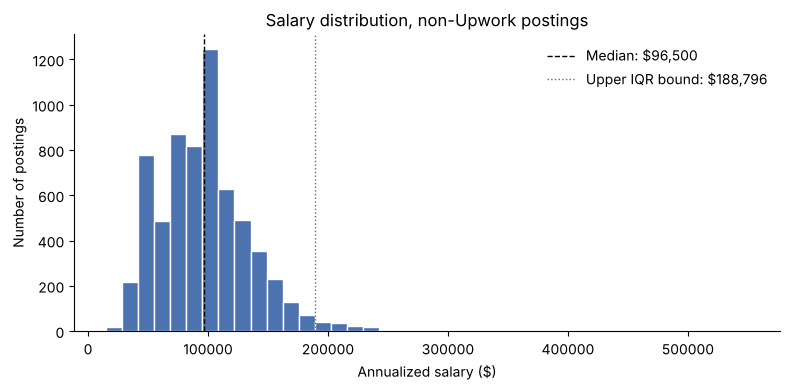

Median: $96,500  |  Mean: $96,983  |  132 of 6,470 postings sit beyond the upper IQR bound (2.0%)


In [6]:
sal_clean = sal.dropna()
q1, q3 = sal_clean.quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
n_outliers = ((sal_clean < lower) | (sal_clean > upper)).sum()

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(sal_clean, bins=40, color="#4C72B0", edgecolor="white")
ax.axvline(sal_clean.median(), color="black", linestyle="--", linewidth=1,
           label=f"Median: ${sal_clean.median():,.0f}")
ax.axvline(upper, color="dimgray", linestyle=":", linewidth=1,
           label=f"Upper IQR bound: ${upper:,.0f}")
ax.set_xlabel("Annualized salary ($)")
ax.set_ylabel("Number of postings")
ax.set_title("Salary distribution, non-Upwork postings")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

print(f"Median: ${sal_clean.median():,.0f}  |  Mean: ${sal_clean.mean():,.0f}  |  "
      f"{n_outliers} of {len(sal_clean):,} postings sit beyond the upper IQR bound "
      f"({n_outliers/len(sal_clean)*100:.1f}%)")

The bulk of disclosed salaries sit in a fairly tight band around the $96,500 median,
with a long right tail - about 2% of postings sit beyond the upper IQR bound,
including the $550,000 Quantitative Researcher posting surfaced in `03_skills_demand`.
Those aren't data errors; they're the real high-end salary found in this dataset, which
pulled the mean ($96,983) above the median.

### Pay by role bucket

,median,mean,count
title_role,,,
Data Scientist,140400.0,141987.0,350
Data Engineer,130000.0,133481.0,216
Data Specialist/Other,114400.0,121313.0,223
Data Analyst,91778.0,91868.0,5681


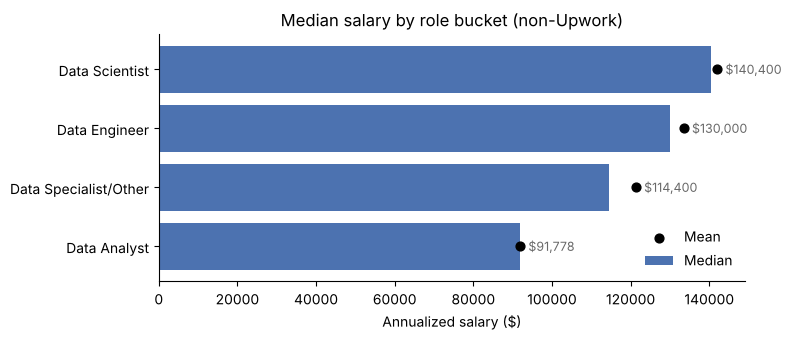

In [7]:
role_pay = (non_gig.groupby("title_role")["salary_standardized"]
            .agg(median="median", mean="mean", count="count")
            .sort_values("median", ascending=False))
display(role_pay.round(0))

fig, ax = plt.subplots(figsize=(8, 3.5))
order = role_pay.index[::-1]
bars = ax.barh(order, role_pay.loc[order, "median"], color="#4C72B0", label="Median")
ax.scatter(role_pay.loc[order, "mean"], order, color="black", zorder=5, s=40, label="Mean")
ax.set_xlabel("Annualized salary ($)")
ax.set_title("Median salary by role bucket (non-Upwork)")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
for bar, label in zip(bars, order):
    anno_x = max(bar.get_width(), role_pay.loc[label, "mean"])
    ax.annotate(f"${role_pay.loc[label, 'median']:,.0f}",
                xy=(anno_x, bar.get_y() + bar.get_height() / 2),
                xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color="dimgray")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

Pay tracks the same split `03_skills_demand` found in skills: Data Scientist leads at
a $140,400 median, Data Engineer follows at $130,000, and Data Analyst -- the vast
majority of the market by volume -- sits lowest at $91,778. Data Specialist/Other
lands in between ($114,400), consistent with that bucket containing the
governance/architect/executive niches surfaced earlier, which skew well-paid -- its
mean ($121,313) sits well above its own median, the widest median-mean gap of the
four buckets, a sign that a handful of very high earners (the Quantitative
Researcher and executive titles) are pulling the average up.

### Pay by seniority

,median,mean,count
title_seniority,,,
Staff,157000.0,156135.0,29
Principal,147500.0,151417.0,74
Director,135000.0,149887.0,32
Manager,133294.0,128766.0,94
Lead,130000.0,128420.0,257
Senior,97500.0,108504.0,1312
Not specified,87050.0,91834.0,4406
Junior,55000.0,65599.0,86
Entry-level,52000.0,58981.0,62


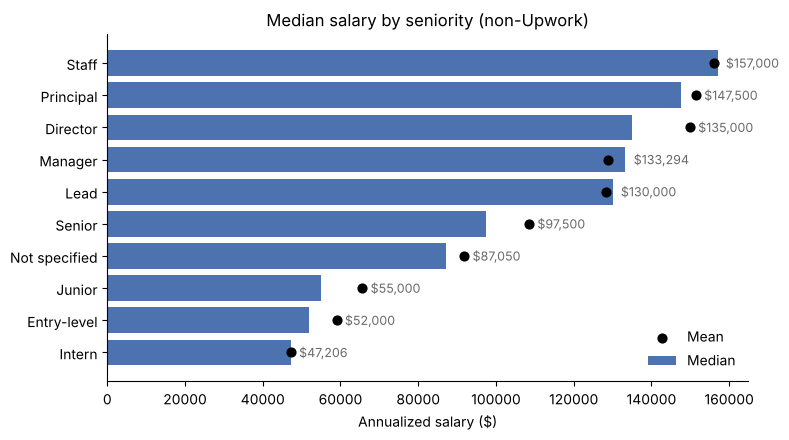

In [8]:
seniority_order = ["Staff", "Principal", "Director", "Manager", "Lead", "Senior",
                   "Not specified", "Junior", "Entry-level", "Intern"]
seniority_pay = (non_gig.groupby("title_seniority")["salary_standardized"]
                 .agg(median="median", mean="mean", count="count")
                 .reindex(seniority_order))
display(seniority_pay.round(0))

fig, ax = plt.subplots(figsize=(8, 4.5))
order = seniority_order[::-1]
bars = ax.barh(order, seniority_pay.loc[order, "median"], color="#4C72B0", label="Median")
ax.scatter(seniority_pay.loc[order, "mean"], order, color="black", zorder=5, s=40, label="Mean")
ax.set_xlabel("Annualized salary ($)")
ax.set_title("Median salary by seniority (non-Upwork)")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
for bar, label in zip(bars, order):
    anno_x = max(bar.get_width(), seniority_pay.loc[label, "mean"])
    ax.annotate(f"${seniority_pay.loc[label, 'median']:,.0f}",
                xy=(anno_x, bar.get_y() + bar.get_height() / 2),
                xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color="dimgray")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

A clean, monotonic ladder from Intern ($47,206) up to Staff ($157,000) -- seniority
words in a title track real pay, as you'd hope. The one thing worth flagging: "Not
specified" ($87,050, n=4,406) sits *below* Senior ($97,500) but close to it, and it's
by far the largest group. Since `03_skills_demand` already showed 73% of all postings
carry no seniority word, this median is really describing a wide mix of unlabeled
mid-level and senior roles, not a distinct tier of its own.

The mean/median gap is also worth a glance: Director's mean ($149,887) runs well
above its median ($135,000) on a small sample (n=32), and Junior's mean ($65,599) sits
notably above its median ($55,000) too -- both signs of a right-skewed tail rather
than a typo, same pattern as the overall distribution in the histogram above.

### Pay by skill

,skill,median_with,n_with,median_without,n_without
0,Spark,114400.0,267,95000.0,6203
1,AWS,109200.0,497,93912.0,5973
2,Python,103781.0,2021,90000.0,4449
3,SQL,96500.0,3914,83200.0,2556
4,Tableau,96500.0,2219,90000.0,4251
5,Excel,85000.0,2313,98800.0,4157
6,Word,75250.0,530,96500.0,5940


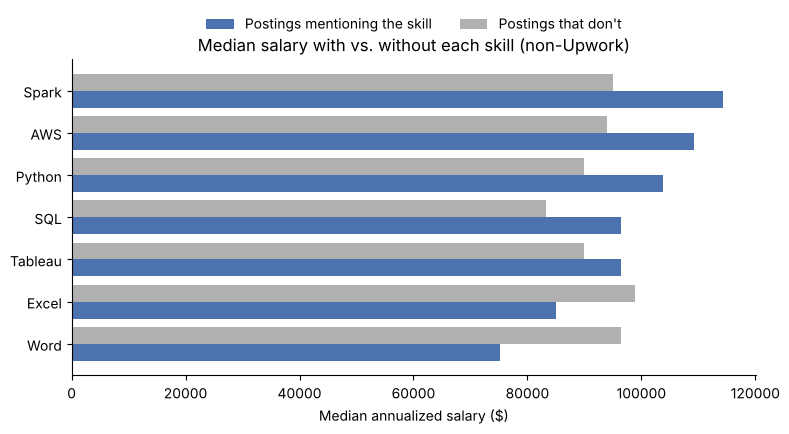

In [9]:
skill_list = ["spark", "aws", "python", "sql", "tableau", "excel", "word"]
skill_labels = {"spark": "Spark", "aws": "AWS", "python": "Python", "sql": "SQL",
                "tableau": "Tableau", "excel": "Excel", "word": "Word"}

rows = []
for skill in skill_list:
    has = non_gig["skills_list"].apply(lambda lst: skill in lst)
    # n_with/n_without count postings that have BOTH the skill tag and salary data --
    # the actual sample the median is computed from, not just skill-mention counts.
    rows.append({
        "skill": skill_labels[skill],
        "median_with": non_gig.loc[has, "salary_standardized"].median(),
        "n_with": int(non_gig.loc[has, "salary_standardized"].notna().sum()),
        "median_without": non_gig.loc[~has, "salary_standardized"].median(),
        "n_without": int(non_gig.loc[~has, "salary_standardized"].notna().sum()),
    })
skill_pay = pd.DataFrame(rows).sort_values("median_with", ascending=False)
display(skill_pay.round(0))

fig, ax = plt.subplots(figsize=(8, 4.5))
y = np.arange(len(skill_pay))
order = skill_pay.iloc[::-1].reset_index(drop=True)
ax.barh(y - 0.2, order["median_with"], height=0.4, color="#4C72B0", label="Postings mentioning the skill")
ax.barh(y + 0.2, order["median_without"], height=0.4, color="#B0B0B0", label="Postings that don't")
ax.set_yticks(y)
ax.set_yticklabels(order["skill"])
ax.set_xlabel("Median annualized salary ($)")
ax.set_title("Median salary with vs. without each skill (non-Upwork)")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, 1.18), ncol=2)
plt.tight_layout()
plt.show()

This is the same cloud/pipeline-vs-office-tool split `03_skills_demand`'s heatmap
showed in *frequency* by role, now showing up directly in *pay*: Spark ($114,400) and
AWS ($109,200) carry a real premium over not mentioning them, while Excel ($85,000)
and Word ($75,250) sit below their own "without" baselines. None of this means Excel
makes you less valuable -- it means Excel is disproportionately common in the
Analyst bucket, which is itself the lowest-paid role bucket above, and skill tokens
here are a proxy for role mix, not an independent pay driver on their own.

## Part 2: Upwork - freelancing as a separate path

`02_market_landscape` already established that Upwork postings are gig/contract work
(96.5% Contractor or Contractor-and-Temp, vs. almost none Full-time), 100% remote, and
overwhelmingly lack a seniority word. The numbers below look at what that gig work
actually pays, on its own terms, rather than next to traditional salaries.

In [ ]:
Uupwork = df[df["via_clean"] == "Upwork"].copy()
up_hr = upwork["salary_hourly"]
print(f"{up_hr.notna().sum():,} of {len(upwork):,} Upwork postings list a rate "
      f"({up_hr.notna().mean()*100:.1f}%) -- a much higher disclosure rate than "
      f"traditional postings, since a freelance rate is the first thing a gig lists.")

hourly_share = (upwork.loc[up_hr.notna(), "salary_rate"] == "an hour").mean() * 100
print(f"{hourly_share:.0f}% of those are listed as an hourly rate (vs. a yearly or "
      f"monthly figure) -- which is why this section uses salary_hourly directly "
      f"instead of the annualized salary_standardized field used in Part 1.")

3,618 of 7,505 Upwork postings list a rate (48.2%) -- a much higher disclosure rate than traditional postings, since a freelance rate is the first thing a gig lists.
100% of those are listed as an hourly rate (vs. a yearly or monthly figure) -- which is why this section uses salary_hourly directly instead of the annualized salary_standardized field used in Part 1.


Upwork is an online marketplace where businesses and individuals hire freelancers for
project- or contract-based work - a different market segment from traditional,
salary-based jobs. This section analyzes Upwork postings separately, using Upwork's
standard pay unit: dollars per hour.
Note: The pay rate data for Upwork postings may not be confirmed rate and could be the freelancer's asking rate.

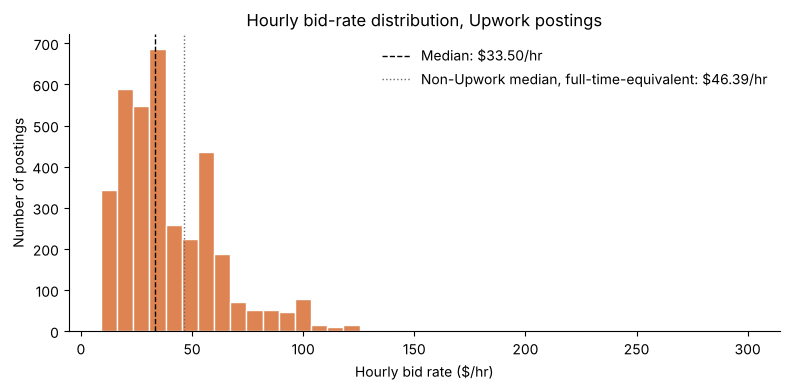

Median: $33.50/hr  |  Mean: $40.33/hr  |  that's 72% of the non-Upwork median's full-time-equivalent hourly rate.


In [11]:
up_hr_clean = up_hr.dropna()
non_gig_hourly_equiv = sal_clean.median() / 2080  # for reference only, see takeaway below

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(up_hr_clean, bins=40, color="#DD8452", edgecolor="white")
ax.axvline(up_hr_clean.median(), color="black", linestyle="--", linewidth=1,
           label=f"Median: ${up_hr_clean.median():,.2f}/hr")
ax.axvline(non_gig_hourly_equiv, color="dimgray", linestyle=":", linewidth=1,
           label=f"Non-Upwork median, full-time-equivalent: ${non_gig_hourly_equiv:,.2f}/hr")
ax.set_xlabel("Hourly bid rate ($/hr)")
ax.set_ylabel("Number of postings")
ax.set_title("Hourly bid-rate distribution, Upwork postings")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

print(f"Median: ${up_hr_clean.median():,.2f}/hr  |  Mean: ${up_hr_clean.mean():,.2f}/hr  |  "
      f"that's {up_hr_clean.median() / non_gig_hourly_equiv * 100:.0f}% of the non-Upwork "
      f"median's full-time-equivalent hourly rate.")

Upwork's median hourly rate ($33.50/hr) runs about 72% of what the non-Upwork
median annualized salary works out to on a full-time-equivalent basis ($46.39/hr) --
almost the same ratio this notebook originally found by annualizing both sides, which
is a reassuring cross-check rather than a coincidence worth over-reading. The
distribution has a noticeably fatter left side than Part 1's chart -- plenty of gigs
bid well under $25/hr -- which tracks with per-task freelance pricing rather than a
benchmarked salary band. Still worth remembering this is *before* whatever cut the
platform itself takes, which isn't in this dataset at all.

In [12]:
upwork_role_pay = (upwork.groupby("title_role")["salary_hourly"]
                   .agg(median="median", count="count")
                   .sort_values("median", ascending=False))
display(upwork_role_pay.round(2))

,median,count
title_role,,
Data Scientist,45.00,103
Data Analyst,33.50,2631
Data Specialist/Other,33.50,830
Data Engineer,30.25,54


Data Scientist gigs bid highest ($45.00/hr, n=103) -- but notice how tight the rest of
the range is: Analyst and Specialist/Other both land on exactly $33.50/hr, and
Engineer (n=54, a small sample on Upwork) is only slightly lower at $30.25/hr. Compare
that to Part 1, where the same four buckets spread proportionally much further apart
-- role bucket barely moves Upwork's rate the way it moves a traditional salary.

In [13]:
up_rows = []
for skill in skill_list:
    has = upwork["skills_list"].apply(lambda lst: skill in lst)
    up_rows.append({
        "skill": skill_labels[skill],
        "median_with": upwork.loc[has, "salary_hourly"].median(),
        "n_with": int(upwork.loc[has, "salary_hourly"].notna().sum()),
        "median_without": upwork.loc[~has, "salary_hourly"].median(),
        "n_without": int(upwork.loc[~has, "salary_hourly"].notna().sum()),
    })
upwork_skill_pay = pd.DataFrame(up_rows)
display(upwork_skill_pay.round(2))

,skill,median_with,n_with,median_without,n_without
0,Spark,26.25,10,33.5,3608
1,AWS,30.00,60,33.5,3558
2,Python,32.50,424,33.5,3194
3,SQL,32.50,560,33.5,3058
4,Tableau,32.50,339,33.5,3279
5,Excel,32.50,663,33.5,2955
6,Word,33.00,59,33.5,3559


This is the clearest contrast in the whole notebook: on Upwork, every skill's "with"
median sits at or *below* its own "without" median (Spark, AWS -- both thin samples
here, n=10 and n=60 -- included), where Part 1 showed a clean, meaningful spread from
Word ($75,250) up to Spark ($114,400). Upwork rates appear to cluster around a common
"data work" hourly rate (roughly $32.50-$33.50/hr) regardless of which specific skill
is listed, instead of pricing specialization the way traditional employment does.

## Conclusion

Only 16.3% of postings disclose pay at all, and that figure is itself skewed by
Upwork's much higher disclosure rate -- which is why this notebook split into two
separate analyses rather than one blended set of numbers.

**Traditional job postings** (Part 1) show pay scaling the way you'd expect from a
real labor market: role bucket (Data Scientist $140,400 down to Data Analyst
$91,778), seniority (a clean ladder from Intern to Staff), and skill (cloud/pipeline
tools like Spark and AWS carrying a real premium over office tools like Word) all
move the median in a consistent, explicable direction. Specialization and seniority
get rewarded, and the median/mean gap -- widest for Data Specialist/Other and for
Director -- consistently points back to the same small set of very high earners.

**Upwork** (Part 2) is a structurally different path to earn in this field, not a
worse version of the same one -- and its pay is reported in its own native unit here
(every priced Upwork posting lists an hourly rate, not a salary) rather than forced
onto an annualized scale that assumes full-time, year-round hours a freelancer may
not actually work. Its median hourly rate runs about 72% of the non-Upwork median's
full-time-equivalent rate, but more strikingly, neither role bucket nor specific skill
moves that number much -- rates cluster tightly around a common hourly ask regardless
of what's listed. That's consistent with a marketplace where freelancers set their own
price for generalized "data work" rather than an employer benchmarking a role against
a market salary band.

Read together with the branching-paths framing from `03_skills_demand`: a data
career doesn't just branch by industry vertical, skill combination, or leadership
track within traditional employment -- freelancing is its own, separate branch,
with its own economics and even its own pay unit, where specialization doesn't move
the number the way it does everywhere else in this dataset.